In [4]:
import sys
import os

import numpy as np

import pandas as pd


sys.path.append(os.path.join(os.getcwd(), 'import'))

from utils import read_utils
from utils import plot_utils
from utils import train_utils
from utils import artificializer

from models import hgm_sep as hgm
from models import clm_sep as clm

In [5]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(artificializer)
importlib.reload(clm)
importlib.reload(hgm)

<module 'models.hgm_sep' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/Workspaces/UNIVIE/JetBrains/DataSpell/MSc_Thesis/worm-2025-fieseler/import/models/hgm_sep.py'>

In [6]:
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_')
filenames, continuous_behaviors, discrete_states, eigenworms, kymographs, traces = read_utils.get_data(path)

path_gfp = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gfp')
filenames_gfp, continuous_behaviors_gfp, discrete_states_gfp, eigenworms_gfp, kymographs_gfp, traces_gfp = read_utils.get_data(path_gfp)

for i in range(len(filenames)):
	mask = eigenworms[i].notna().all(axis=1)
	#continuous_behaviors[i] = continuous_behaviors[i][mask]
	discrete_states[i] = discrete_states[i][mask]
	eigenworms[i] = eigenworms[i][mask]
	traces[i] = traces[i][mask]

	#kymographs[i] = kymographs[i][mask]
	#filenames[i] = filenames[i][mask]

for i in range(len(filenames_gfp)):
	mask = eigenworms_gfp[i].notna().all(axis=1)
	#continuous_behaviors_gfp[i] = continuous_behaviors_gfp[i][mask]
	discrete_states_gfp[i] = discrete_states_gfp[i][mask]
	eigenworms_gfp[i] = eigenworms_gfp[i][mask]
	traces_gfp[i] = traces_gfp[i][mask]

	#kymographs_gfp[i] = kymographs_gfp[i][mask]
	#filenames_gfp[i] = filenames_gfp[i][mask]

In [7]:
filenames_art = list()
discrete_states_art = discrete_states.copy()
eigenworms_art = eigenworms.copy()
modes_manifold_art = list()
traces_residual_art = list()
traces_art = list()
for i in range(len(filenames)):
	art_filename, art_mode_manifold, art_trace_residual, art_trace, art_params = artificializer.artificialize(hgm, filenames[i], traces[i].columns, eigenworms_art[i], discrete_states_art[i])
	filenames_art.append(art_filename)
	modes_manifold_art.append(art_mode_manifold)
	traces_residual_art.append(art_trace_residual)
	traces_art.append(art_trace)

# a_traces.to_csv(f'./in/{a_name}_traces.csv', index=False)
# a_traces_residual.to_csv(f'./in/{a_name}_tracesresidual.csv', index=False)

In [8]:
worm_id = -1
for i in range(len(filenames)):
	if 'VA01' in traces[i].columns:
		worm_id = i
		break

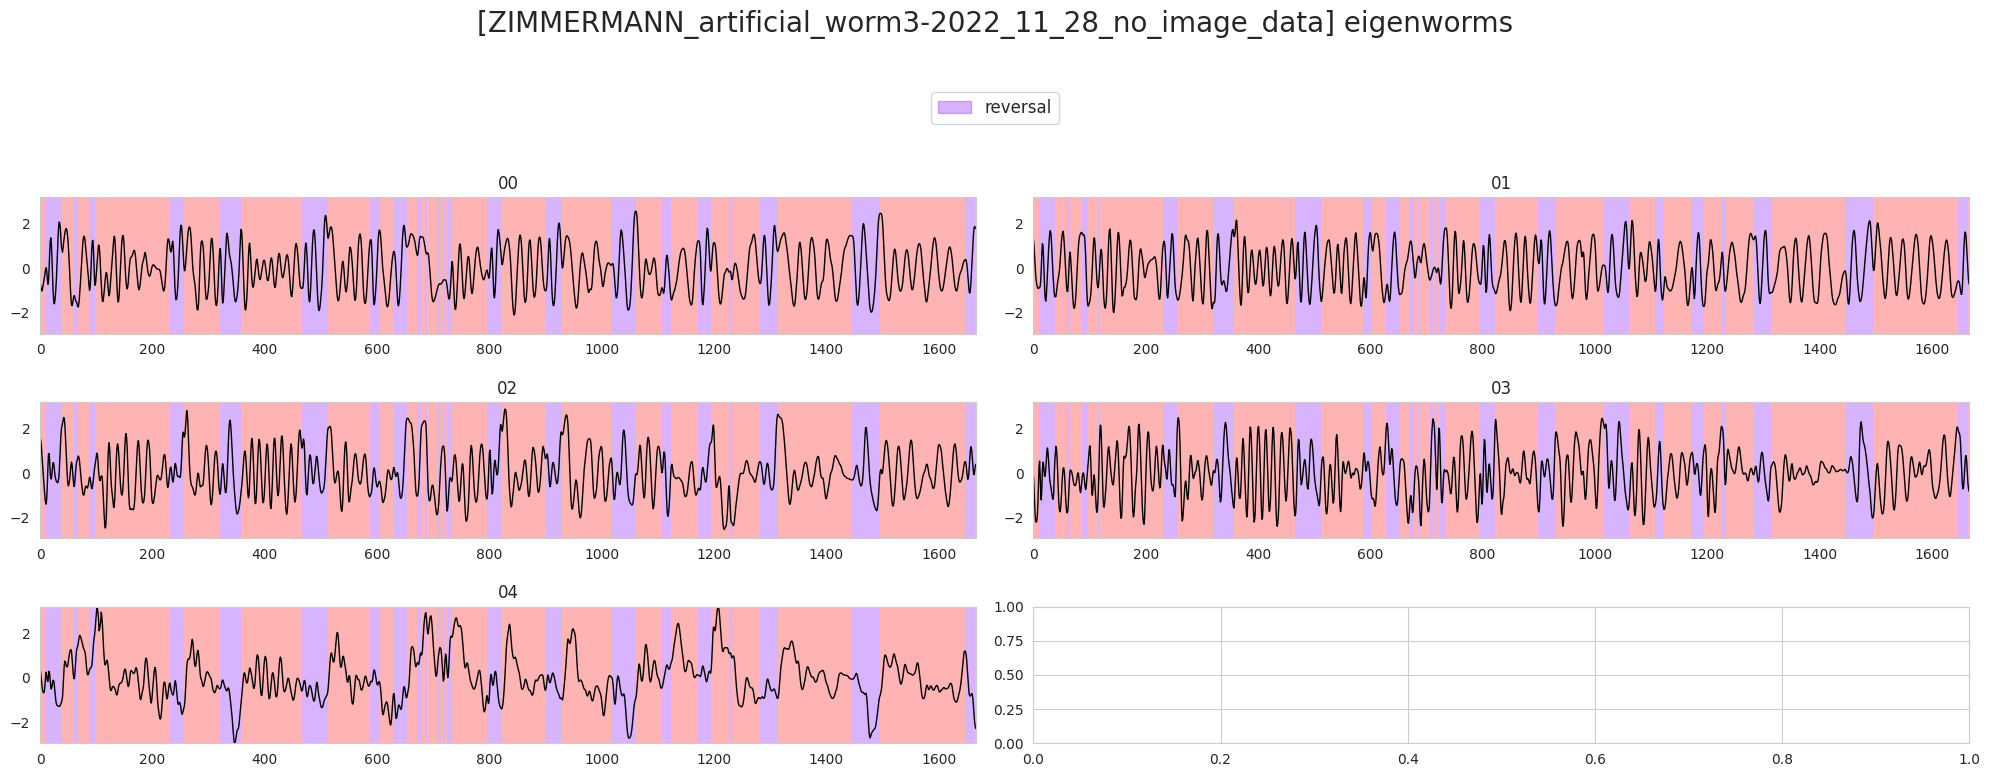

In [9]:
plot_utils.plot_traces(eigenworms_art[worm_id], discrete_states_art[worm_id]['REV'], f'[{filenames_art[worm_id]}] eigenworms', n_plots=5)

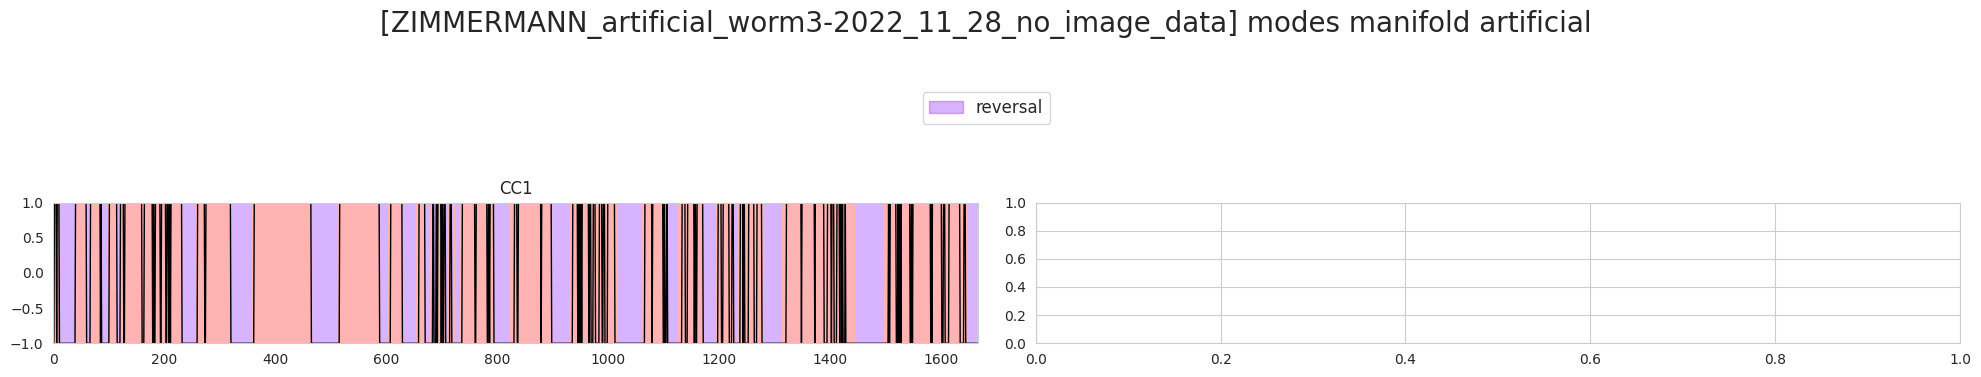

In [10]:
plot_utils.plot_traces(modes_manifold_art[worm_id], discrete_states_art[worm_id]['REV'], f'[{filenames_art[worm_id]}] modes manifold artificial', n_plots=1)

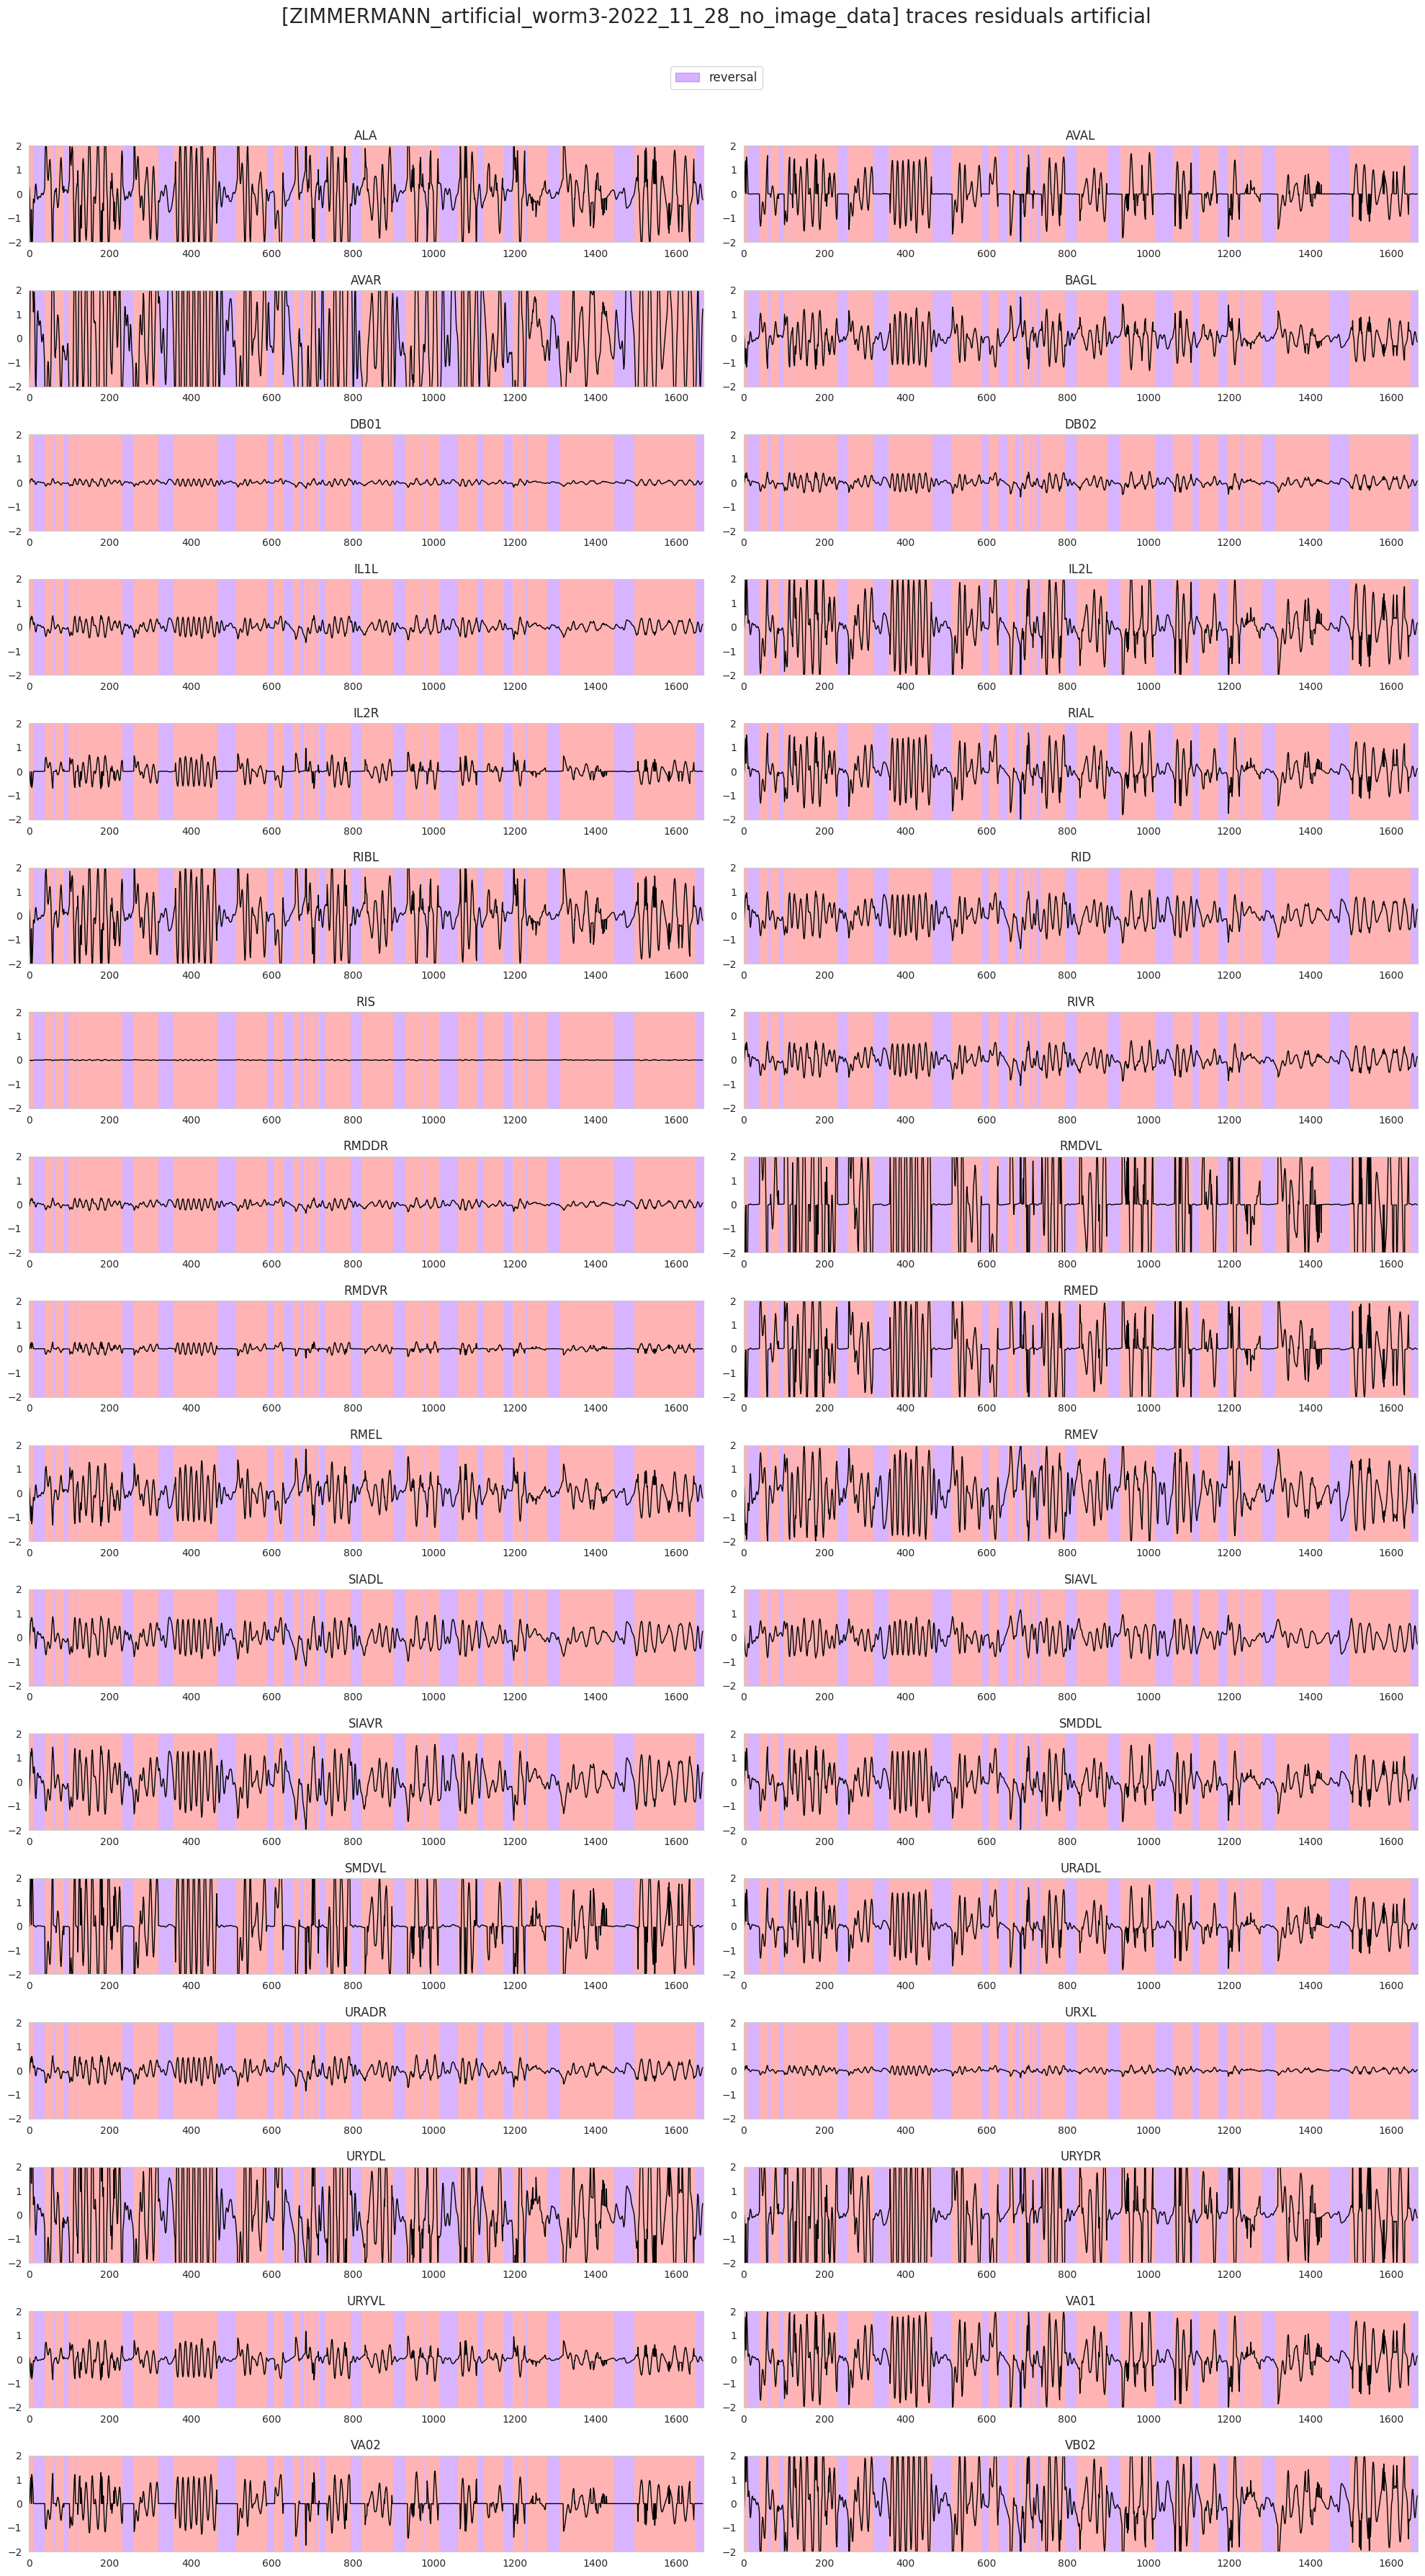

In [11]:
plot_utils.plot_traces(traces_residual_art[worm_id], discrete_states_art[worm_id]['REV'], f'[{filenames_art[worm_id]}] traces residuals artificial', n_plots=None, limits=(-2, 2))

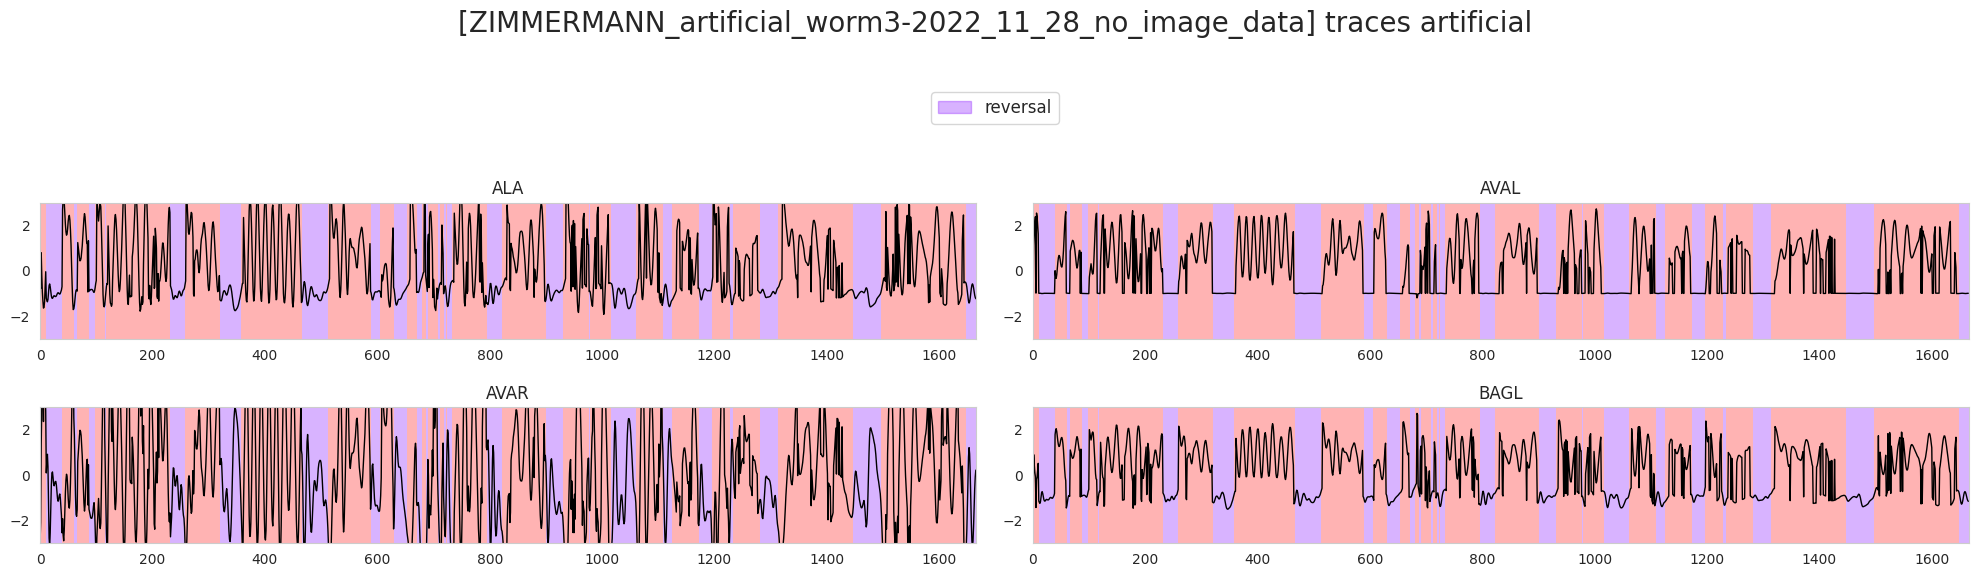

In [12]:
plot_utils.plot_traces(traces_art[worm_id], discrete_states_art[worm_id]['REV'], f'[{filenames_art[worm_id]}] traces artificial', n_plots=4, limits=(-3, 3))

In [13]:
if False: raise Exception

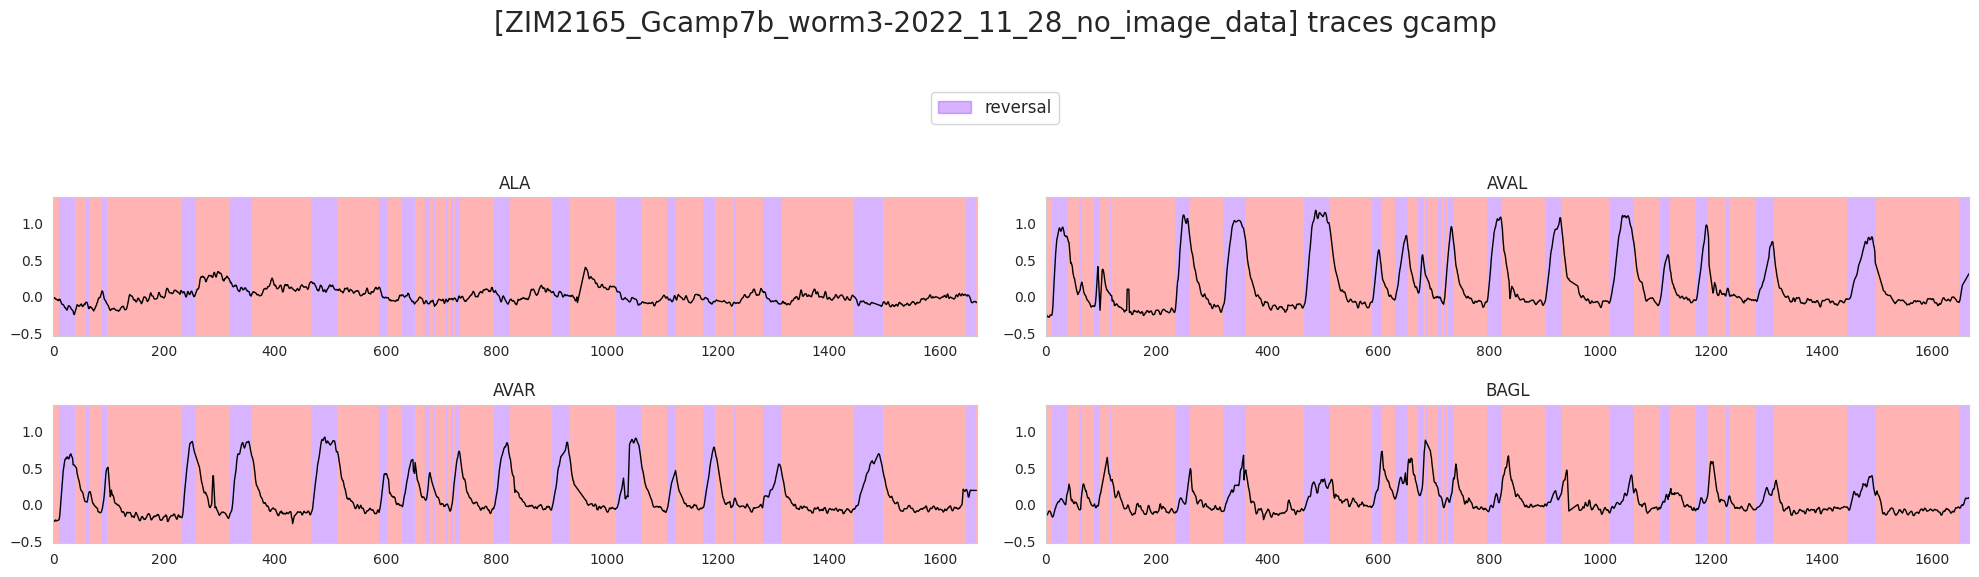

In [14]:
plot_utils.plot_traces(traces[worm_id], discrete_states[worm_id]['REV'], f'[{filenames[worm_id]}] traces gcamp', n_plots=4)

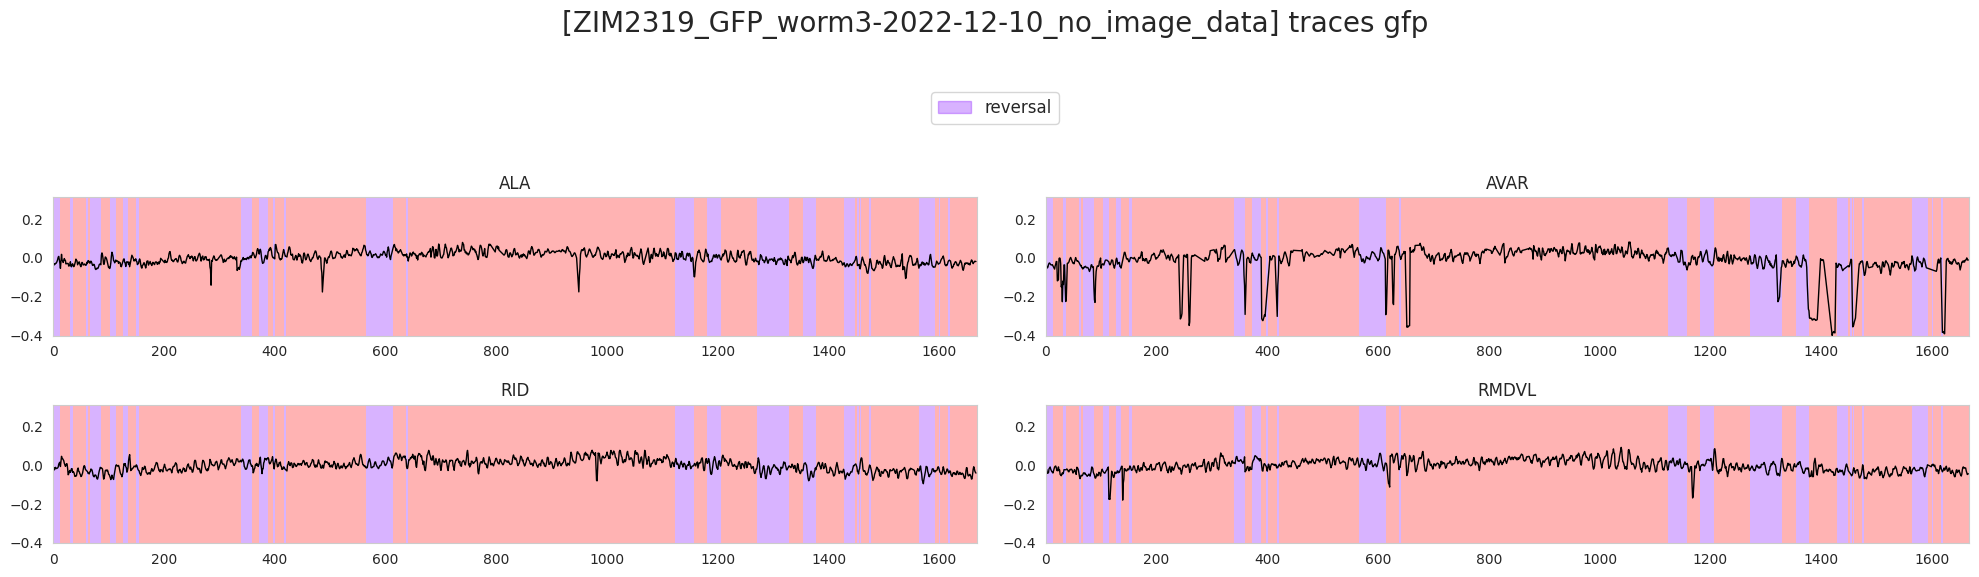

In [15]:
plot_utils.plot_traces(traces_gfp[worm_id], discrete_states_gfp[worm_id]['REV'], f'[{filenames_gfp[worm_id]}] traces gfp', n_plots=4)

In [16]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

modes_manifold, traces_manifold, cca_loadings_man, vars_expl_man, vars_expl_man_rs = train_utils.get_manifolds([traces[worm_id]],
																											   [discrete_states[worm_id][selection]],
																				   n_cc=2, n_pc=5)

trace_residual = pd.DataFrame(data=traces[worm_id].values - traces_manifold[0].values, columns=traces[worm_id].columns)

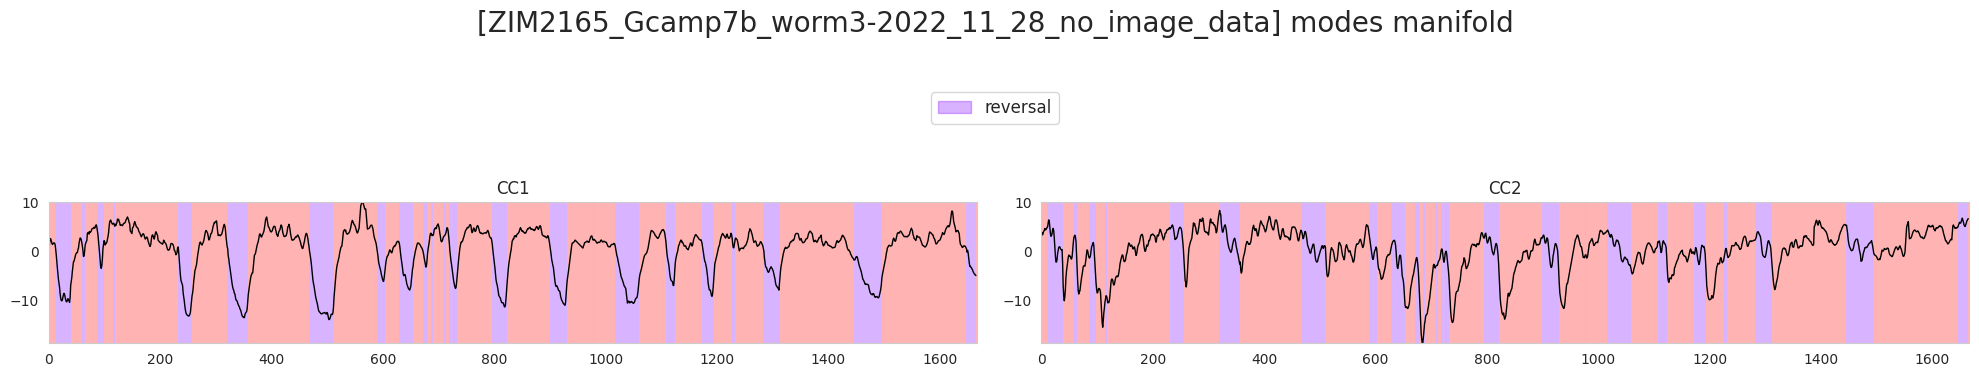

In [17]:
plot_utils.plot_traces(modes_manifold[0], discrete_states[worm_id]['REV'], f'[{filenames[worm_id]}] modes manifold', n_plots=2)

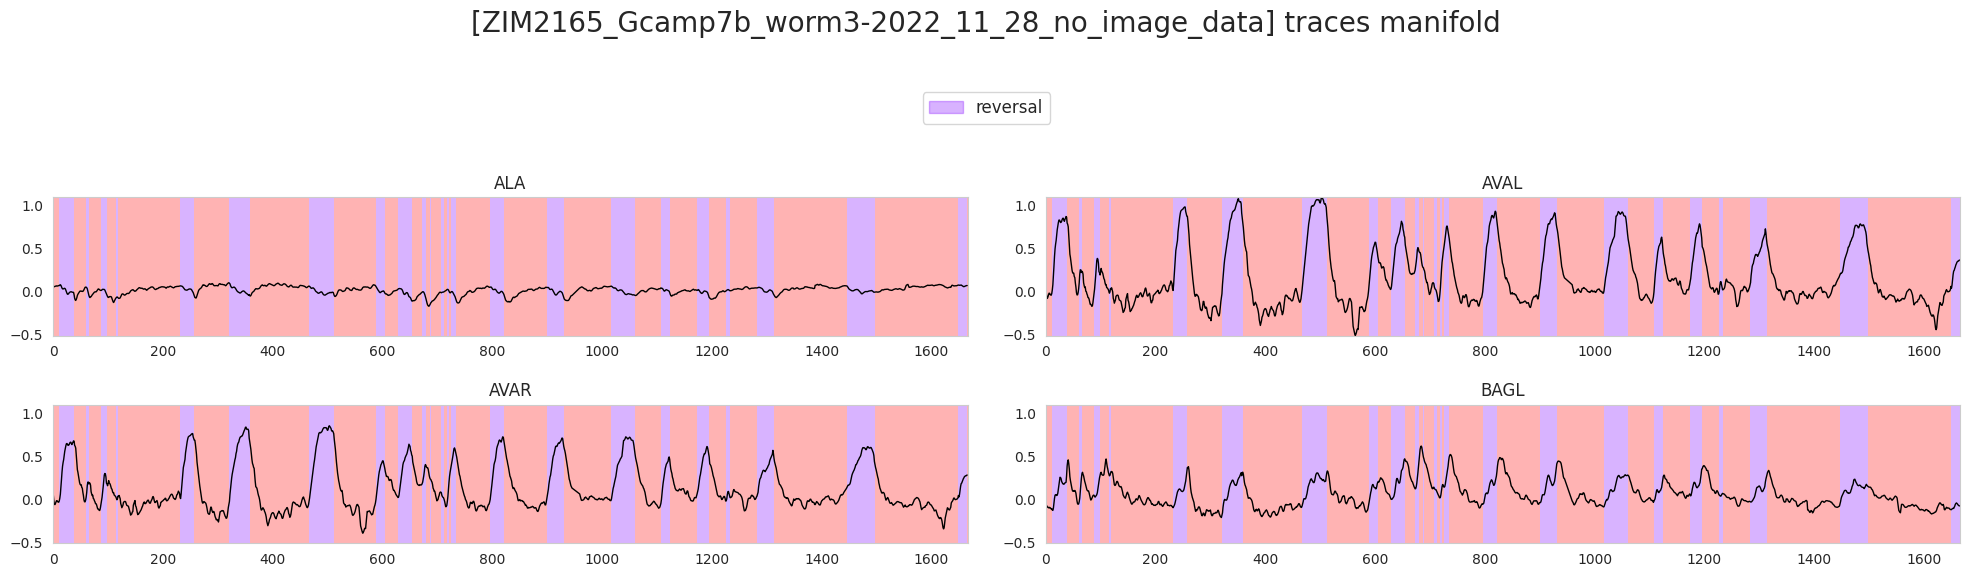

In [18]:
plot_utils.plot_traces(traces_manifold[0], discrete_states[worm_id]['REV'], f'[{filenames[worm_id]}] traces manifold', n_plots=4)

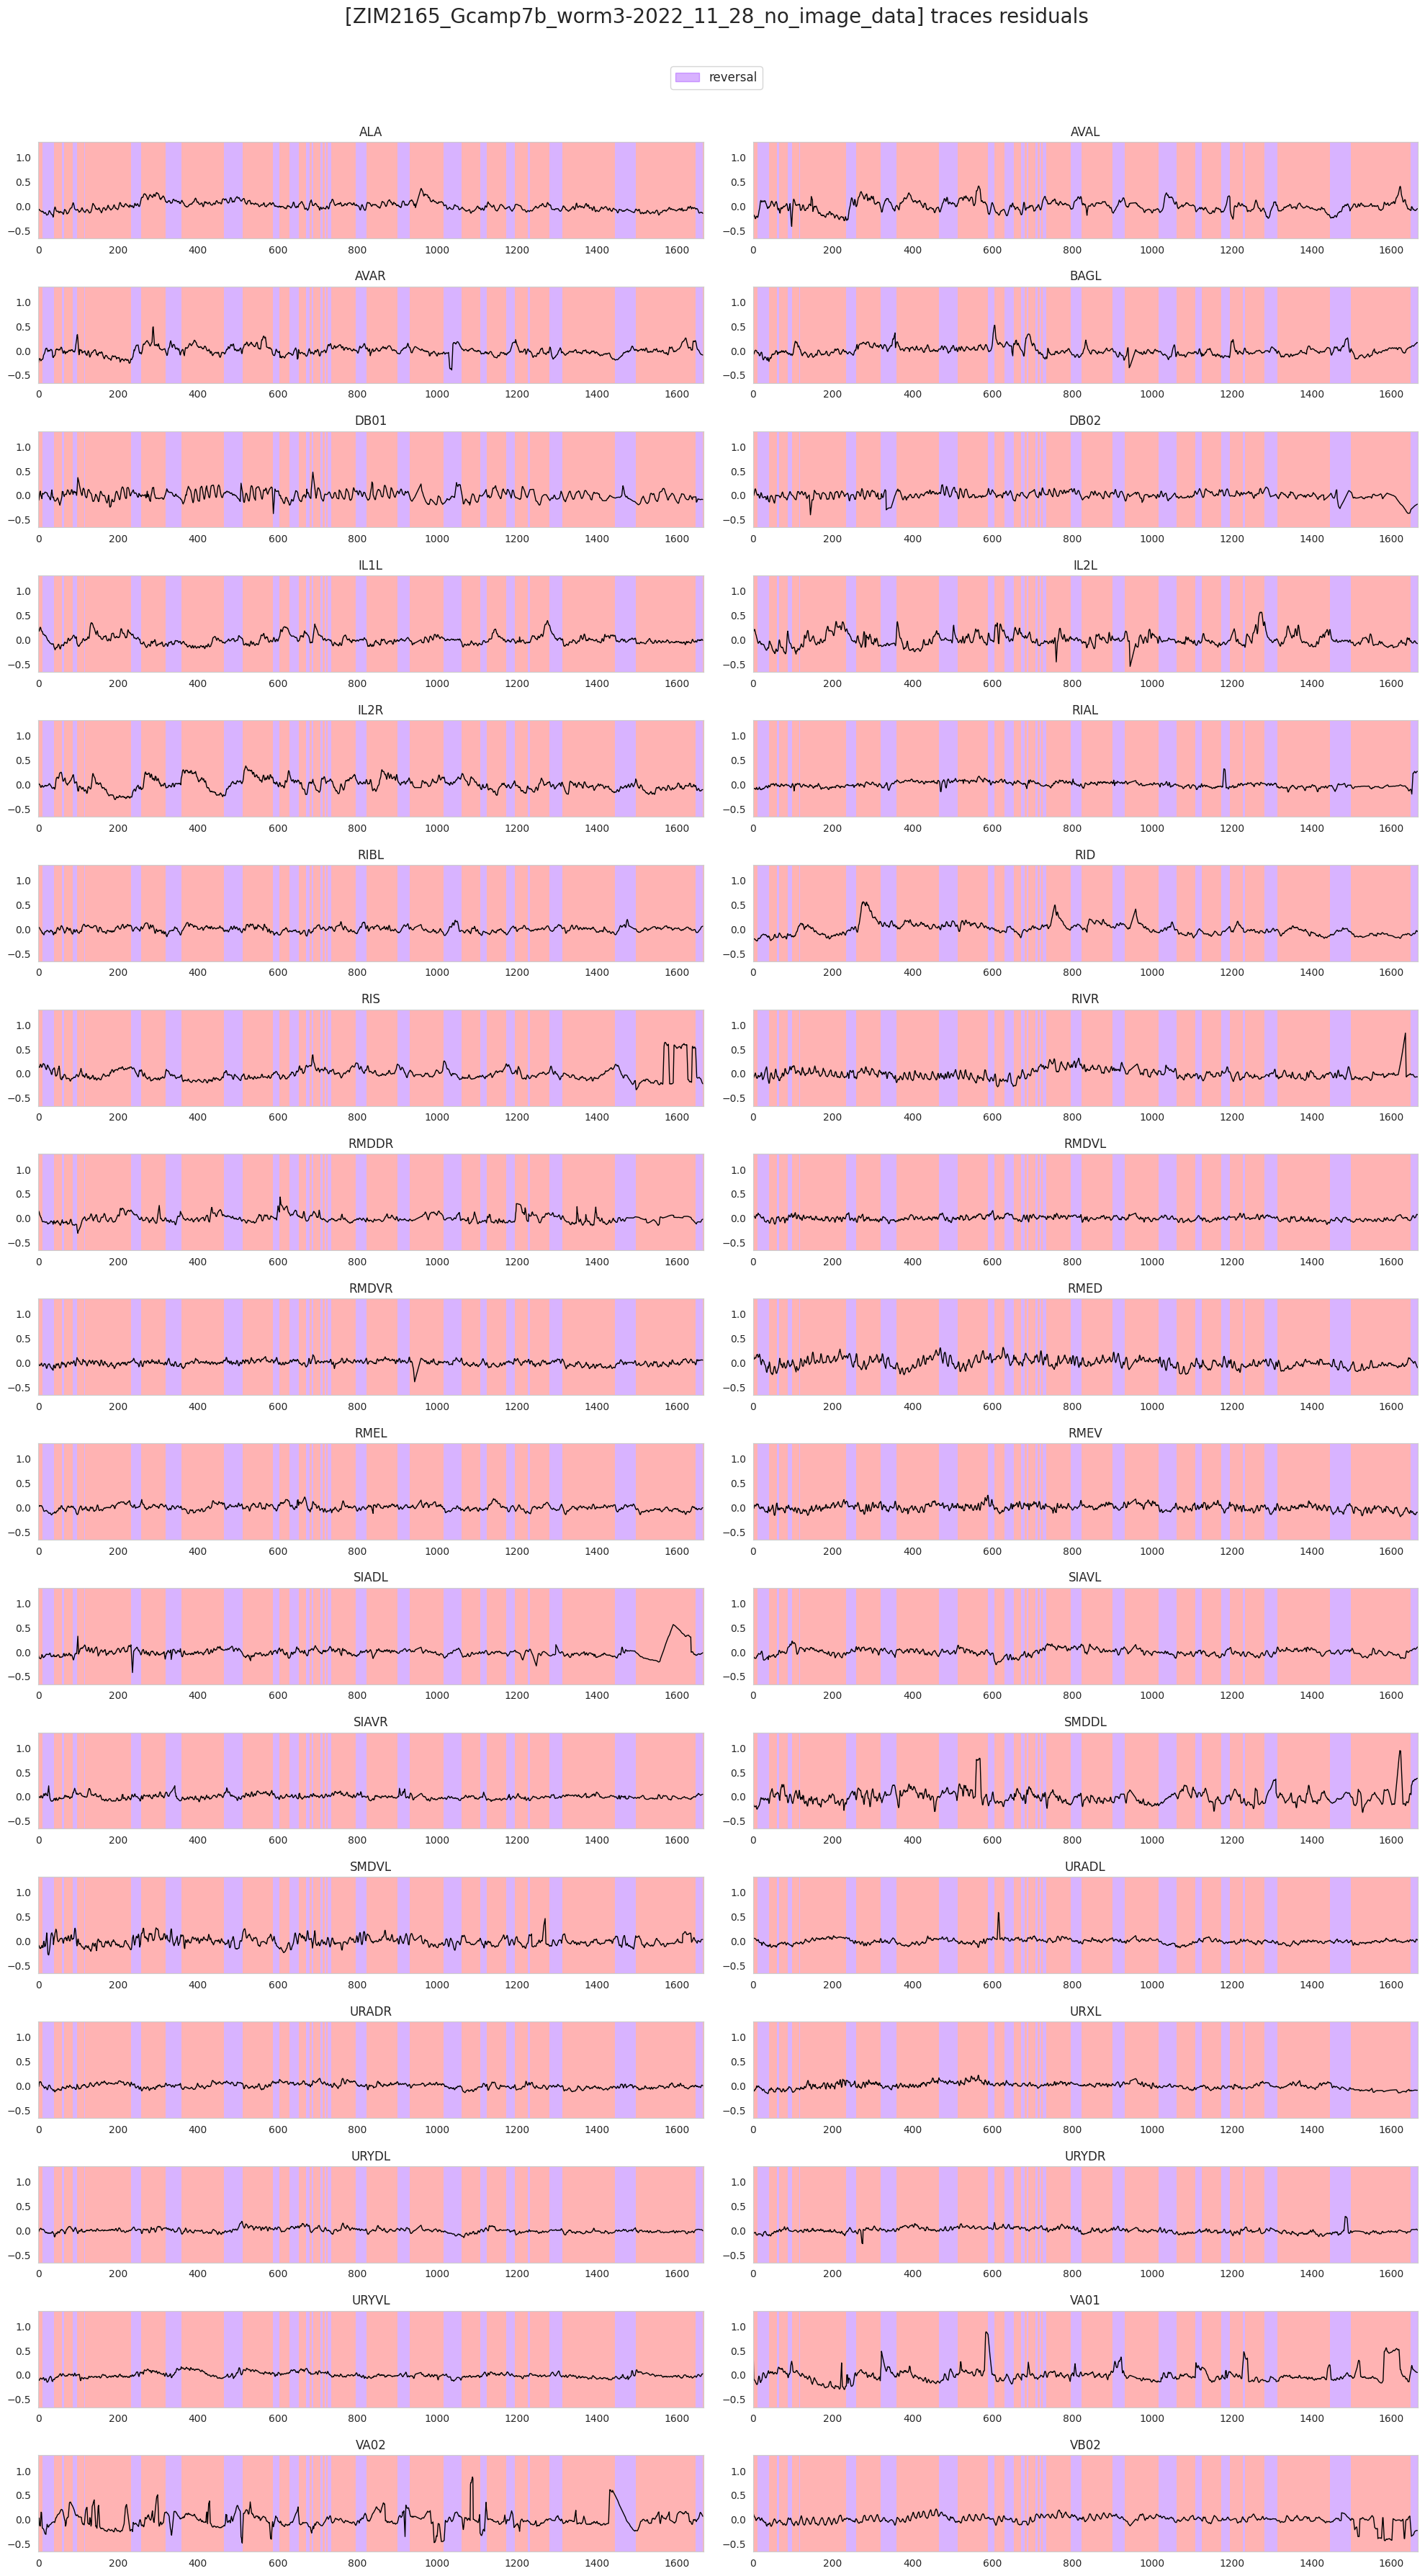

In [19]:
plot_utils.plot_traces(trace_residual, discrete_states[worm_id]['REV'], f'[{filenames[worm_id]}] traces residuals', n_plots=None)

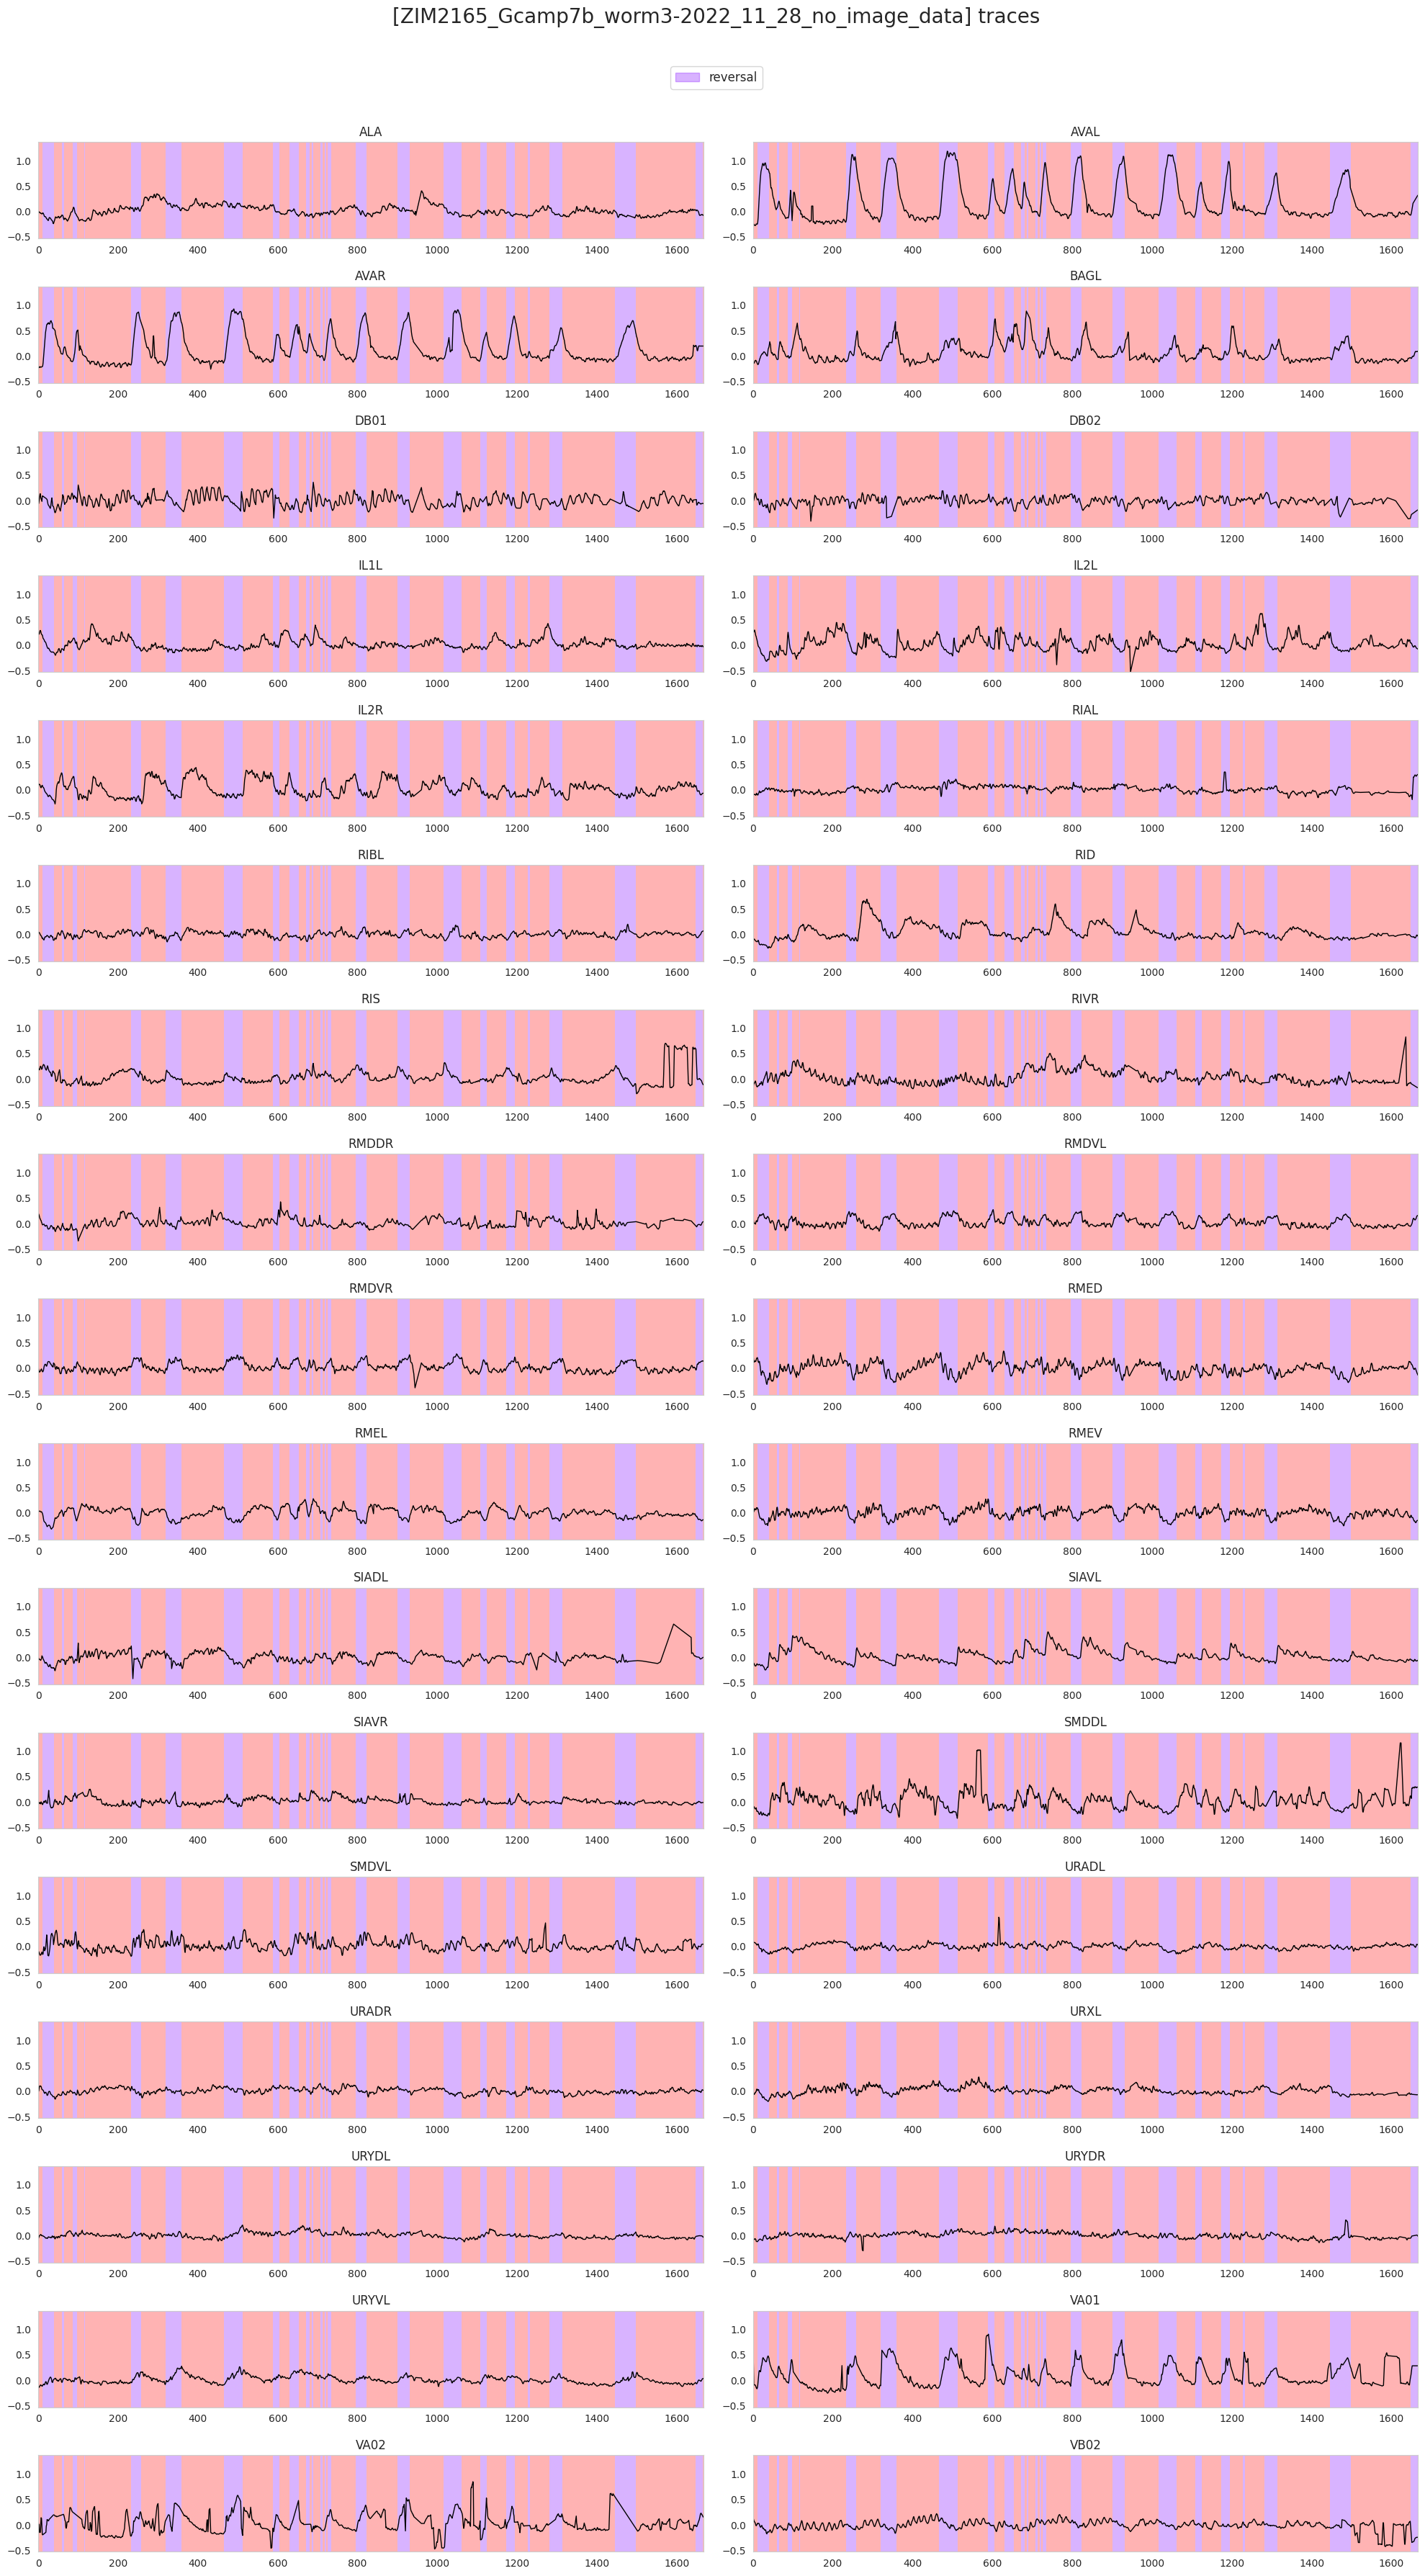

In [20]:
plot_utils.plot_traces(traces[worm_id], discrete_states[worm_id]['REV'], f'[{filenames[worm_id]}] traces', n_plots=None)